# Filtrado de muones (tiempo de vuelo)

Separa los eventos que son muones de los picos de ruido. El trigger es negativo (`--thr -100` mV) y un muón da un
pulso **solo negativo**: la señal puede tener un pequeño rebote, pero no sube mucho por encima de la línea de base.
La interferencia, en cambio, es una oscilación que cruza el umbral para abajo **y también para arriba**
(+200 a +500 mV).

Criterio, con un único umbral de selección `THR_SEL` (celda de abajo):
- el pulso tiene que bajar de $-$`THR_SEL` en los **tres** canales;
- ningún canal puede subir de $+$`THR_SEL` (si sube, es ruido).

`THR_SEL = 100` mV reproduce el trigger del hardware (`--thr -100`); `THR_SEL = 120` es más exigente. Los criterios
de tiempo que usan un umbral (sección 5) usan este mismo valor. Cambiarlo y correr todo (*Run All*).

La lista de eventos aceptados se guarda en `muones_filtrados_thr<THR_SEL>.csv`.

In [42]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

THR_SEL = 120      # [mV] umbral de selección: pulso < −THR_SEL en los 3 canales y nada > +THR_SEL. Probar 100 o 120.

DIR_TOF = Path('../grupo_7_jueves/medidas/tof')
ARCHIVO_SALIDA = Path(f'muones_filtrados_thr{THR_SEL:g}.csv')

CANALES = (1, 2, 3)
NOMBRE_CANAL = {1: 'CH1 (arriba)', 2: 'CH2 (medio)', 3: 'CH3 (abajo)'}
COLOR_CANAL = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a'}
BORDE = 5          # muestras que se descartan en cada punta de la ventana (artefactos del DRS4)

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 11, 'legend.frameon': False,
    'axes.grid': True, 'grid.color': '#e4e3dd', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110,
})

## 1. Lectura

De cada archivo `*_eventos.csv` se toma el encabezado (`run_id`, umbral) y la tabla de eventos. De cada
`*_ondas.txt` se calcula, por canal, el máximo y el mínimo de la forma de onda respecto de la línea de base
(`base{ch}_mV` del CSV).

In [43]:
RE_EVENTO = re.compile(rb'^Event #(\d+)[^\n]*\n', re.M)


def leer_encabezado(ruta):
    enc = {}
    with open(ruta, encoding='utf-8', errors='replace') as f:
        for linea in f:
            if not linea.startswith('#'):
                break
            m = re.match(r'#\s*([^:]+?)\s*:\s*(.*)', linea)
            if m:
                enc[m.group(1)] = m.group(2).strip()
    return enc


def umbral_mV(enc):
    m = re.search(r'--thr\s+(-?[\d.]+)', enc.get('comando', ''))
    return float(m.group(1)) if m else -50.0       # -50 mV es el default de drs_tof


def leer_ondas(ruta):
    """{evento: array (n_muestras, 6)} con columnas t1, v1, t2, v2, t3, v3."""
    datos = ruta.read_bytes()
    ms = list(RE_EVENTO.finditer(datos))
    ondas = {}
    for k, m in enumerate(ms):
        fin = ms[k + 1].start() if k + 1 < len(ms) else len(datos)
        ondas[int(m.group(1))] = np.array(datos[m.end():fin].split(), dtype=float).reshape(-1, 2 * len(CANALES))
    return ondas


tablas = []
ONDAS = {}
for ruta in sorted(DIR_TOF.glob('*_eventos.csv')):
    enc = leer_encabezado(ruta)
    run = enc.get('run_id', ruta.stem)
    df = pd.read_csv(ruta, comment='#', on_bad_lines='skip')
    df['run'] = run
    df['thr_mV'] = umbral_mV(enc)

    ruta_ondas = ruta.with_name(ruta.name.replace('_eventos.csv', '_ondas.txt'))
    ondas = leer_ondas(ruta_ondas) if ruta_ondas.exists() else {}
    for ch in CANALES:
        df[f'vmax{ch}_mV'] = np.nan
        df[f'vmin{ch}_mV'] = np.nan
    for i, e in enumerate(df['evento']):
        if e not in ondas:
            continue
        ONDAS[(run, e)] = ondas[e]
        for k, ch in enumerate(CANALES):
            v = ondas[e][BORDE:-BORDE, 2 * k + 1] - df.at[i, f'base{ch}_mV']
            df.at[i, f'vmax{ch}_mV'] = v.max()
            df.at[i, f'vmin{ch}_mV'] = v.min()
    tablas.append(df)

ev = pd.concat(tablas, ignore_index=True).set_index(['run', 'evento']).sort_index()
ev['vmax_mV'] = ev[[f'vmax{ch}_mV' for ch in CANALES]].max(axis=1)     # máximo positivo de los 3 canales
RUNS = ev.index.unique('run').tolist()
print(f'{len(ev)} eventos en {len(RUNS)} corridas, {ev["vmax_mV"].notna().sum()} con forma de onda')

5432 eventos en 2 corridas, 5432 con forma de onda


## 2. Filtro con el umbral de selección

Un evento es muón si en los tres canales la forma de onda baja de $-$`THR_SEL` (respecto de la base), si ningún
canal sube de $+$`THR_SEL` y si los tres tienen $t_{\rm CFD}$ en el CSV.

In [44]:
umbral_pos = pd.Series(float(THR_SEL), index=ev.index)
ev['cruza_arriba'] = ev['vmax_mV'] > THR_SEL
ev['llega_abajo'] = (ev[[f'vmin{ch}_mV' for ch in CANALES]] <= -THR_SEL).all(axis=1)
ev['completo'] = ev[[f't_cfd{ch}_ns' for ch in CANALES]].notna().all(axis=1)
ev['muon'] = ~ev['cruza_arriba'] & ev['llega_abajo'] & ev['completo'] & ev['vmax_mV'].notna()

por_run = lambda s: s.groupby(level='run').sum()
resumen = pd.DataFrame({
    'eventos': ev.groupby(level='run').size(),
    f'cruzan +{THR_SEL:g} mV': por_run(ev['cruza_arriba']),
    f'algún canal no baja de −{THR_SEL:g} mV': por_run(~ev['llega_abajo']),
    'sin t_CFD en algún canal': por_run(~ev['completo']),
    'muones': por_run(ev['muon']),
})
resumen.loc['total'] = resumen.sum()
print(f'THR_SEL = {THR_SEL:g} mV')
display(resumen)

THR_SEL = 120 mV


,eventos,cruzan +120 mV,algún canal no baja de −120 mV,sin t_CFD en algún canal,muones
run,,,,,
tof_d61.2cm_20261029_180950,5305,5284,5,1,16
tof_d61.2cm_20261029_194928,127,20,49,2,58
total,5432,5304,54,3,74


### Distribución del máximo positivo

Los muones quedan agrupados por debajo de ~150 mV (rebote y ruido de línea de base); la interferencia aparece
desde ~180 mV hasta la saturación (~500 mV). La línea marca el corte usado. Si el corte se come la cola
de los muones (CH2 es el canal más ruidoso), se puede subir `UMBRAL_POS` hasta el hueco entre las dos poblaciones.

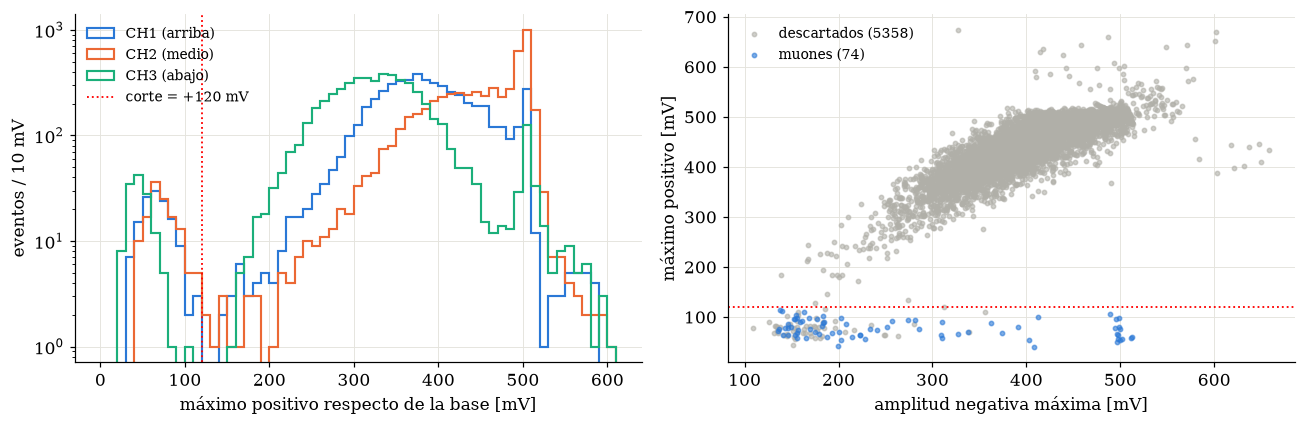

In [45]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))

bins = np.arange(0, 620, 10)
for ch in CANALES:
    a.hist(ev[f'vmax{ch}_mV'].dropna(), bins=bins, histtype='step', lw=1.4,
           color=COLOR_CANAL[ch], label=NOMBRE_CANAL[ch])
a.axvline(umbral_pos.iloc[0], color='red', lw=1.2, ls=':', label=f'corte = +{umbral_pos.iloc[0]:g} mV')
a.set_yscale('log')
a.set_xlabel('máximo positivo respecto de la base [mV]')
a.set_ylabel('eventos / 10 mV')
a.legend(fontsize=9)

amp = -ev[[f'amp{ch}_mV' for ch in CANALES]].min(axis=1)                # mayor amplitud negativa de los 3
for es_muon, color, nombre in [(False, '#b0afa8', 'descartados'), (True, '#2a78d6', 'muones')]:
    s = ev['muon'] == es_muon
    b.scatter(amp[s], ev.loc[s, 'vmax_mV'], s=8, alpha=0.6, color=color, label=f'{nombre} ({s.sum()})')
b.axhline(umbral_pos.iloc[0], color='red', lw=1.2, ls=':')
b.set_xlabel('amplitud negativa máxima [mV]')
b.set_ylabel('máximo positivo [mV]')
b.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 3. Ejemplos

Formas de onda de algunos eventos aceptados (arriba) y descartados por cruzar hacia arriba (abajo). Punteadas: el
umbral del trigger (gris) y el corte positivo (rojo). Cambiar `SEMILLA` para ver otros.

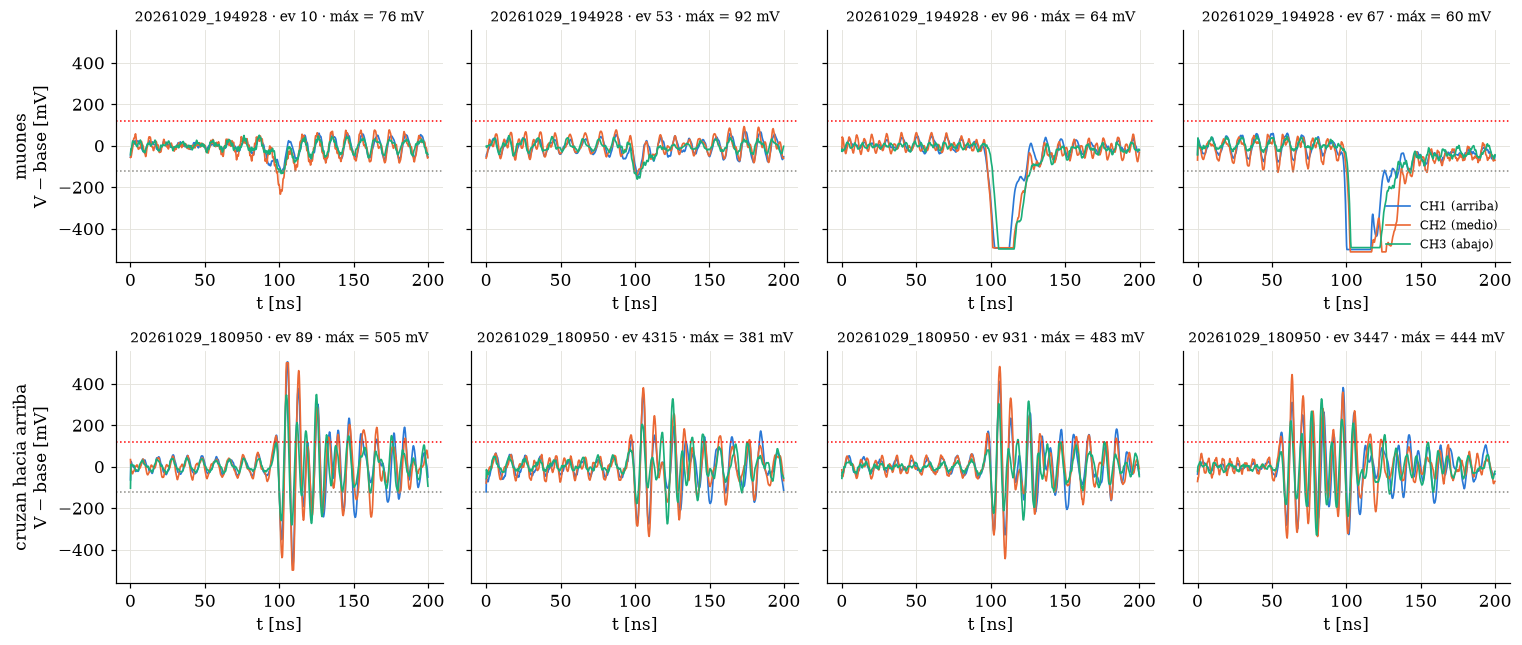

In [46]:
SEMILLA = 0
N_EJ = 4


def dibujar_onda(ax, clave):
    f = ev.loc[clave]
    arr = ONDAS[clave]
    for k, ch in enumerate(CANALES):
        ax.plot(arr[:, 2 * k], arr[:, 2 * k + 1] - f[f'base{ch}_mV'], color=COLOR_CANAL[ch], lw=1.1,
                label=NOMBRE_CANAL[ch])
    ax.axhline(-THR_SEL, color='#8a8984', lw=1, ls=':')
    ax.axhline(umbral_pos.loc[clave], color='red', lw=1, ls=':')
    ax.set_title(f'{clave[0][-15:]} · ev {clave[1]} · máx = {f["vmax_mV"]:.0f} mV', fontsize=9)
    ax.set_xlabel('t [ns]')


rng = np.random.default_rng(SEMILLA)
grupos = [('muones', ev.index[ev['muon']]), ('cruzan hacia arriba', ev.index[ev['cruza_arriba']])]
fig, axs = plt.subplots(2, N_EJ, figsize=(14, 6), sharey=True)
for fila, (nombre, idx) in zip(axs, grupos):
    elegidos = rng.choice(len(idx), size=min(N_EJ, len(idx)), replace=False) if len(idx) else []
    for ax, j in zip(fila, elegidos):
        dibujar_onda(ax, idx[j])
    fila[0].set_ylabel(f'{nombre}\nV − base [mV]')
axs[0, -1].legend(fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

## 4. Guardar

Se guarda la lista de eventos aceptados con sus tiempos y amplitudes en `muones_filtrados.csv`.

In [47]:
cols = (['timestamp', 'dt31_ns', 'dt21_ns', 'dt32_ns']
        + [f't_cfd{ch}_ns' for ch in CANALES] + [f'amp{ch}_mV' for ch in CANALES] + ['vmax_mV'])
muones = ev.loc[ev['muon'], cols]
muones.to_csv(ARCHIVO_SALIDA)
print(f'{len(muones)} muones guardados en {ARCHIVO_SALIDA}')
display(muones['dt31_ns'].describe().round(2).to_frame().T)

74 muones guardados en muones_filtrados_thr120.csv


,count,mean,std,min,25%,50%,75%,max
dt31_ns,74.0,2.41,2.11,-3.9,1.1,2.15,3.25,8.87


## 5. Análisis de tiempos: criterios de inicio del pulso

Con los muones filtrados se recalcula el tiempo de cada canal a partir de la forma de onda, con distintos criterios.
Se trabaja con $s(t) = -(V - \text{base})$, que es positiva en el pulso, y con $A = \max s$ en el pico. Todos los
cruces se buscan **en el flanco de subida**: se camina hacia atrás desde el pico hasta el primer punto que queda
por debajo del nivel y se interpola linealmente entre las dos muestras. Así no se toman cruces del ruido previo.
Cada canal usa su propio eje temporal calibrado.

| criterio | tiempo |
|---|---|
| **umbral (`THR_SEL`)** | primer cruce del umbral de selección, $s = $ `THR_SEL` (leading edge) |
| **pico** | máximo de $s$, con el vértice de una parábola ajustada a 5 muestras |
| **50 % desde 0** | $s = A/2$ (CFD 50 %, lo mismo que calcula `drs_tof`) |
| **50 % desde el umbral** | $s = $ `THR_SEL` $+ (A - $ `THR_SEL`$)/2$ |
| *propuestos:* | |
| **CFD 20 %** | $s = 0{,}2\,A$: más cerca del comienzo real del pulso y sin *walk* por amplitud |
| **umbral bajo (50 mV)** | $s = 50$ mV fijo, al borde del ruido de la línea de base |
| **extrapolación a 0** | recta ajustada al flanco entre 20 % y 80 % de $A$ (≥ 3 muestras), extrapolada hasta $s = 0$: estima el comienzo del pulso. Se descarta si cae más de 5 ns antes del cruce del 20 % |
| **centroide** | promedio de $t$ pesado con $s$ en los puntos alrededor del pico con $s > A/2$ |

Un muón es **superlumínico** si su $\Delta t_{31} = t_3 - t_1$ es menor que el tiempo de vuelo a $\beta = 1$
($d_{13}/c = 2{,}04$ ns) por más de un paso temporal del DRS4 ($\approx 0{,}195$ ns a 5,12 GS/s).

**Ojo:** no está restado ningún offset entre canales (`OFFSET_NS = 0`, cables y PMTs), así que tanto los valores
medios como la fracción de superlumínicos se corren con ese offset.

In [48]:
C_M_NS = 0.299792458        # velocidad de la luz [m/ns]
D13, SD13 = 0.612, 0.014    # separación CH1-CH3 [m]
TOF_C = D13 / C_M_NS        # tiempo de vuelo a beta = 1 [ns]
OFFSET_NS = 0.0             # offset de dt31 [ns]. Todavía no medido.
AMP_SAT = 480               # [mV]. Por encima de esto el pulso está saturado y el pico queda aplanado.


def cruce_flanco(t, s, ip, nivel):
    # Cruce de s = nivel en el flanco de subida, caminando hacia atrás desde el pico ip.
    if not (0 < nivel <= s[ip]):
        return np.nan
    j = ip
    while j > 0 and s[j] >= nivel:
        j -= 1
    if s[j] >= nivel:
        return np.nan
    return t[j] + (nivel - s[j]) * (t[j + 1] - t[j]) / (s[j + 1] - s[j])


def t_pico(t, s, ip, m=2):
    k = slice(max(ip - m, 0), ip + m + 1)
    a, b, _ = np.polyfit(t[k] - t[ip], s[k], 2)
    if a >= 0:
        return t[ip]
    return t[ip] + np.clip(-b / (2 * a), t[k][0] - t[ip], t[k][-1] - t[ip])


def t_extrapolado(t, s, ip, A, f_lo=0.2, f_hi=0.8):
    idx = []
    j = ip
    while j > 0 and s[j] >= f_lo * A:
        if s[j] <= f_hi * A:
            idx.append(j)
        j -= 1
    if len(idx) < 3:
        return np.nan
    a, b = np.polyfit(t[idx], s[idx], 1)
    t0 = -b / a if a > 0 else np.nan
    t_lo = cruce_flanco(t, s, ip, f_lo * A)
    return t0 if t_lo - 5 <= t0 <= t_lo else np.nan     # descarta ajustes casi planos que se van lejos


def t_centroide(t, s, ip, A):
    i0 = ip
    while i0 > 0 and s[i0 - 1] > A / 2:
        i0 -= 1
    i1 = ip
    while i1 < len(s) - 1 and s[i1 + 1] > A / 2:
        i1 += 1
    k = slice(i0, i1 + 1)
    return np.sum(t[k] * s[k]) / np.sum(s[k])


def tiempos_canal(t, s, thr):
    ip = BORDE + int(np.argmax(s[BORDE:-BORDE]))
    A = s[ip]
    return {
        f'umbral ({THR_SEL:g} mV)': cruce_flanco(t, s, ip, thr),
        'pico': t_pico(t, s, ip),
        '50 % desde 0': cruce_flanco(t, s, ip, A / 2),
        '50 % desde el umbral': cruce_flanco(t, s, ip, thr + (A - thr) / 2),
        'CFD 20 %': cruce_flanco(t, s, ip, 0.2 * A),
        'umbral bajo (50 mV)': cruce_flanco(t, s, ip, 50.0),
        'extrapolación a 0': t_extrapolado(t, s, ip, A),
        'centroide': t_centroide(t, s, ip, A),
    }


filas = []
for clave in ev.index[ev['muon']]:
    f = ev.loc[clave]
    arr = ONDAS[clave]
    thr = THR_SEL
    for k, ch in enumerate(CANALES):
        s = -(arr[:, 2 * k + 1] - f[f'base{ch}_mV'])
        for metodo, tt in tiempos_canal(arr[:, 2 * k], s, thr).items():
            filas.append((*clave, metodo, ch, tt))

T = (pd.DataFrame(filas, columns=['run', 'evento', 'metodo', 'canal', 't_ns'])
     .pivot(index=['run', 'evento', 'metodo'], columns='canal', values='t_ns'))
DT = (T[3] - T[1] - OFFSET_NS).unstack('metodo')              # dt31 por evento (filas) y método (columnas)
METODOS = list(tiempos_canal(np.arange(20.0), np.r_[np.zeros(8), 200, 150, np.zeros(10)], 100).keys())
DT = DT[METODOS]
# Control: '50 % desde 0' es el mismo criterio que usa drs_tof (fraccion_cfd = 0,5), tiene que dar igual al CSV.
dif = (DT['50 % desde 0'] - (ev.loc[DT.index, 'dt31_ns'] - OFFSET_NS)).abs().max()
print(f'control contra drs_tof: máxima diferencia en Δt31 con "50 % desde 0" = {dif:.1e} ns')

saturado = (ev.loc[DT.index, [f'amp{ch}_mV' for ch in CANALES]].abs() >= AMP_SAT).any(axis=1)
DT_MUESTRA = float(np.median(np.diff(ONDAS[DT.index[0]][:, 0])))
print(f'{len(DT)} muones ({saturado.sum()} con algún canal saturado). Paso temporal = {DT_MUESTRA:.3f} ns, '
      f'TOF(β=1) = {TOF_C:.3f} ns → superlumínico si Δt31 < {TOF_C - DT_MUESTRA:.3f} ns')

control contra drs_tof: máxima diferencia en Δt31 con "50 % desde 0" = 1.2e-04 ns
74 muones (14 con algún canal saturado). Paso temporal = 0.195 ns, TOF(β=1) = 2.041 ns → superlumínico si Δt31 < 1.846 ns


### Resumen por criterio

`N` es la cantidad de muones en los que el criterio da un tiempo en los tres canales (la extrapolación puede fallar). `σ` es el ancho de la
distribución (resolución combinada de los dos canales) y `err` el error del valor medio. $\beta$ se calcula con el $\Delta t_{31}$ medio, $\beta = d_{13}/(c\,\langle\Delta t_{31}\rangle)$, propagando el error de la media y el de $d_{13}$. La fracción de
superlumínicos lleva error binomial.

In [49]:
def resumen_metodos(dt):
    filas = {}
    for m in METODOS:
        x = dt[m].dropna()
        n = len(x)
        sup = (x < TOF_C - DT_MUESTRA).sum()
        p = sup / n
        media, err = x.mean(), x.std(ddof=1) / np.sqrt(n)
        beta = D13 / (C_M_NS * media)
        filas[m] = {'N': n, 'media [ns]': media, 'err [ns]': err,
                    'β': beta, 'err β': beta * np.hypot(SD13 / D13, err / media),
                    'σ [ns]': x.std(ddof=1), 'mediana [ns]': x.median(),
                    'superlumínicos': sup, 'fracción': p, 'err fracción': np.sqrt(p * (1 - p) / n)}
    return pd.DataFrame(filas).T.astype({'N': int, 'superlumínicos': int})


RES = {'todos': resumen_metodos(DT), 'sin saturados': resumen_metodos(DT[~saturado])}
BETA_SUP = D13 / (C_M_NS * (TOF_C - DT_MUESTRA))     # β por encima del cual el muón es superlumínico
display(RES['todos'].round(3))

,N,media [ns],err [ns],β,err β,σ [ns],mediana [ns],superlumínicos,fracción,err fracción
umbral (120 mV),74,2.808,0.342,0.727,0.090,2.942,2.559,26,0.351,0.055
pico,74,3.116,0.367,0.655,0.079,3.154,2.151,31,0.419,0.057
50 % desde 0,74,2.412,0.245,0.846,0.088,2.106,2.149,32,0.432,0.058
50 % desde el umbral,74,2.991,0.345,0.682,0.080,2.969,2.414,29,0.392,0.057
CFD 20 %,74,2.597,0.228,0.786,0.071,1.965,2.139,30,0.405,0.057
umbral bajo (50 mV),74,2.578,0.239,0.792,0.075,2.053,2.190,31,0.419,0.057
extrapolación a 0,69,2.157,0.272,0.946,0.121,2.262,1.938,32,0.464,0.060
centroide,74,3.486,0.278,0.586,0.049,2.392,3.661,20,0.270,0.052


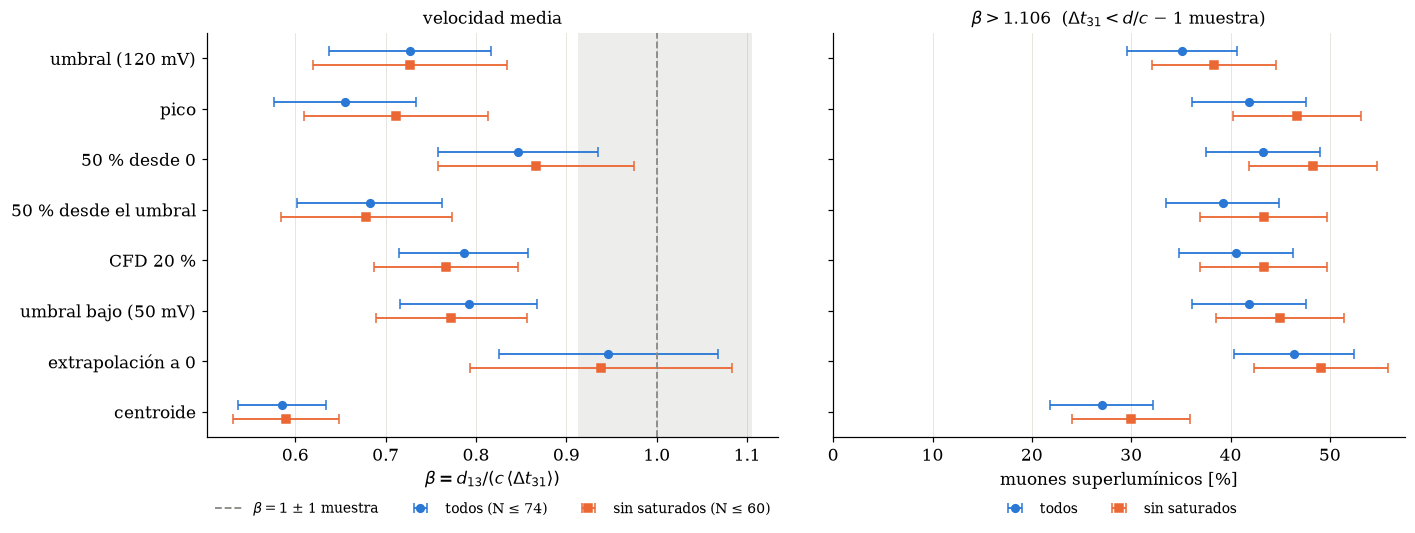

In [50]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
y = np.arange(len(METODOS))
estilos = {'todos': dict(color='#2a78d6', marker='o', dy=-0.14),
           'sin saturados': dict(color='#eb6834', marker='s', dy=+0.14)}

for nombre, r in RES.items():
    e = estilos[nombre]
    a.errorbar(r['β'], y + e['dy'], xerr=r['err β'], fmt=e['marker'], color=e['color'],
               ms=5, capsize=3, lw=1.2, label=f'{nombre} (N ≤ {r["N"].max()})')
    b.errorbar(100 * r['fracción'], y + e['dy'], xerr=100 * r['err fracción'], fmt=e['marker'],
               color=e['color'], ms=5, capsize=3, lw=1.2, label=nombre)

beta_lo = D13 / (C_M_NS * (TOF_C + DT_MUESTRA))
a.axvspan(beta_lo, BETA_SUP, color='#8a8984', alpha=0.15, lw=0)
a.axvline(1, color='#8a8984', lw=1.2, ls='--', label=r'$\beta = 1$ ± 1 muestra')
a.set_xlabel(r'$\beta = d_{13} / (c\,\langle \Delta t_{31} \rangle)$' + (f'  (offset {OFFSET_NS:g} ns)' if OFFSET_NS else ''))
a.set_title('velocidad media', fontsize=11)
a.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)

b.set_xlabel('muones superlumínicos [%]')
b.set_title(rf'$\beta > {BETA_SUP:.3f}$  ($\Delta t_{{31}} < d/c$ − 1 muestra)', fontsize=11)
b.set_xlim(left=0)
b.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2)

a.set_yticks(y, METODOS)
a.invert_yaxis()
for ax in (a, b):
    ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

### Distribuciones de $\beta$ por criterio

$\beta = d_{13}/(c\,\Delta t_{31})$ evento por evento. Los eventos con $\Delta t_{31} \le 0$ no dan velocidad y los de
$\beta > 3$ quedan fuera del gráfico; se cuentan en el título. La línea negra es $\beta$ del $\Delta t_{31}$ medio y
la zona roja, la de superlumínicos.

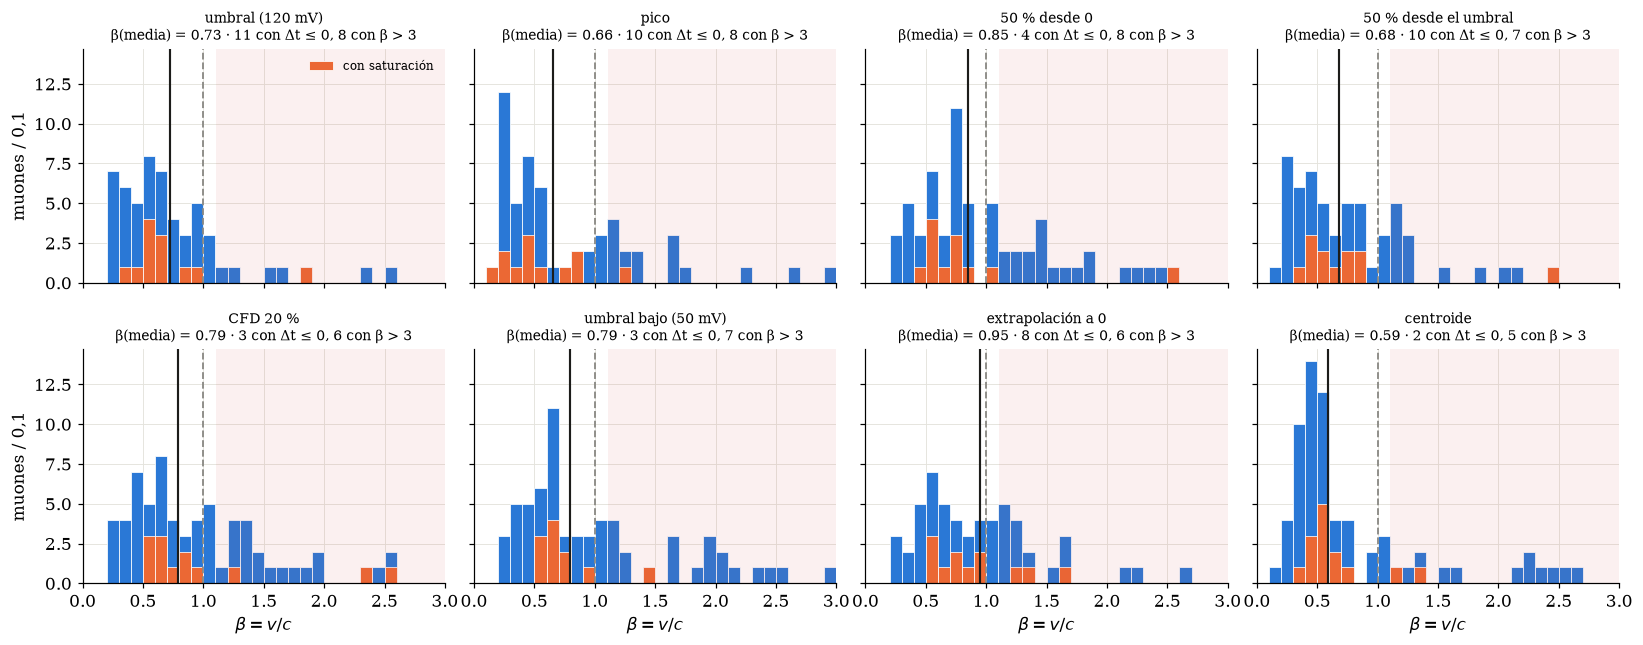

In [51]:
n = len(METODOS)
fig, axs = plt.subplots(2, (n + 1) // 2, figsize=(15, 6), sharex=True, sharey=True)
bins = np.arange(0, 3.01, 0.1)
for ax, m in zip(axs.flat, METODOS):
    x = DT[m].dropna()
    beta = D13 / (C_M_NS * x[x > 0])
    ax.hist(beta, bins=bins, color='#2a78d6', edgecolor='white', lw=0.5)
    ax.hist(beta[saturado.loc[beta.index]], bins=bins, color='#eb6834', edgecolor='white', lw=0.5,
            label='con saturación')
    ax.axvspan(BETA_SUP, 10, color='#d64545', alpha=0.08, lw=0)
    ax.axvline(1, color='#8a8984', lw=1.2, ls='--')
    ax.axvline(D13 / (C_M_NS * x.mean()), color='#1c1c1a', lw=1.4)
    ax.set_title(f'{m}\nβ(media) = {D13 / (C_M_NS * x.mean()):.2f} · '
                 f'{(x <= 0).sum()} con Δt ≤ 0, {(beta > bins[-1]).sum()} con β > 3', fontsize=9)
    ax.set_xlim(bins[0], bins[-1])
for ax in axs.flat[n:]:
    ax.set_visible(False)
for ax in axs[-1]:
    ax.set_xlabel(r'$\beta = v/c$')
for ax in axs[:, 0]:
    ax.set_ylabel('muones / 0,1')
axs.flat[0].legend(fontsize=8)
fig.tight_layout()
plt.show()